In [ ]:
import pandas as pd

# 1. Ingest Data
df_2015 = pd.read_csv('/city_day.csv')
df_2023 = pd.read_csv('/aqi.csv')

# 2. Align columns
df_2023.rename(columns={
    'area': 'City',
    'date': 'Date',
    'aqi_value': 'AQI',
    'air_quality_status': 'AQI_Bucket'
}, inplace=True)

# 3. Align date formats
df_2015['Date'] = pd.to_datetime(df_2015['Date'])
df_2023['Date'] = pd.to_datetime(df_2023['Date'], format='%d-%m-%Y')

# 4. Standardize city names
df_2015['City'] = df_2015['City'].str.strip().str.title()
df_2023['City'] = df_2023['City'].str.strip().str.title()

# 5. Combine into a master dataset
master_df = pd.concat([df_2015, df_2023], ignore_index=True)

# 6. Clean duplicates and missing targets
master_df.drop_duplicates(subset=['City', 'Date'], inplace=True)
master_df.dropna(subset=['AQI'], inplace=True)

# 7. Export the file
master_df.to_csv('/master_aqi_pipeline.csv', index=False)
print("Pipeline exported successfully!")

Pipeline exported successfully!


Saving chandigarh_temporal_features.csv to chandigarh_temporal_features (1).csv
Dataset shape: (1424, 29)

First 5 rows:
         City        Date      PM2.5        PM10         NO        NO2  \
0  Chandigarh  01-01-2020  63.220000  135.760000  46.810000  15.960000   
1  Chandigarh  01-01-2023  57.483333  118.843333  32.276667  15.643333   
2  Chandigarh  01-01-2024  51.746667  101.926667  17.743333  15.326667   
3  Chandigarh  01-02-2020  46.010000   85.010000   3.210000  15.010000   
4  Chandigarh  01-02-2023  38.725000   77.147500   9.092500  16.092500   

         NOx        NH3        CO   SO2  ...  \
0  45.210000  24.730000  1.110000  7.79  ...   
1  31.983333  42.996667  1.013333  7.85  ...   
2  18.756667  61.263333  0.916667  7.91  ...   
3   5.530000  79.530000  0.820000  7.97  ...   
4  12.092500  72.545000  0.790000  8.32  ...   

                                                unit  note  Month  Day  Year  \
0                                                NaN   NaN      1

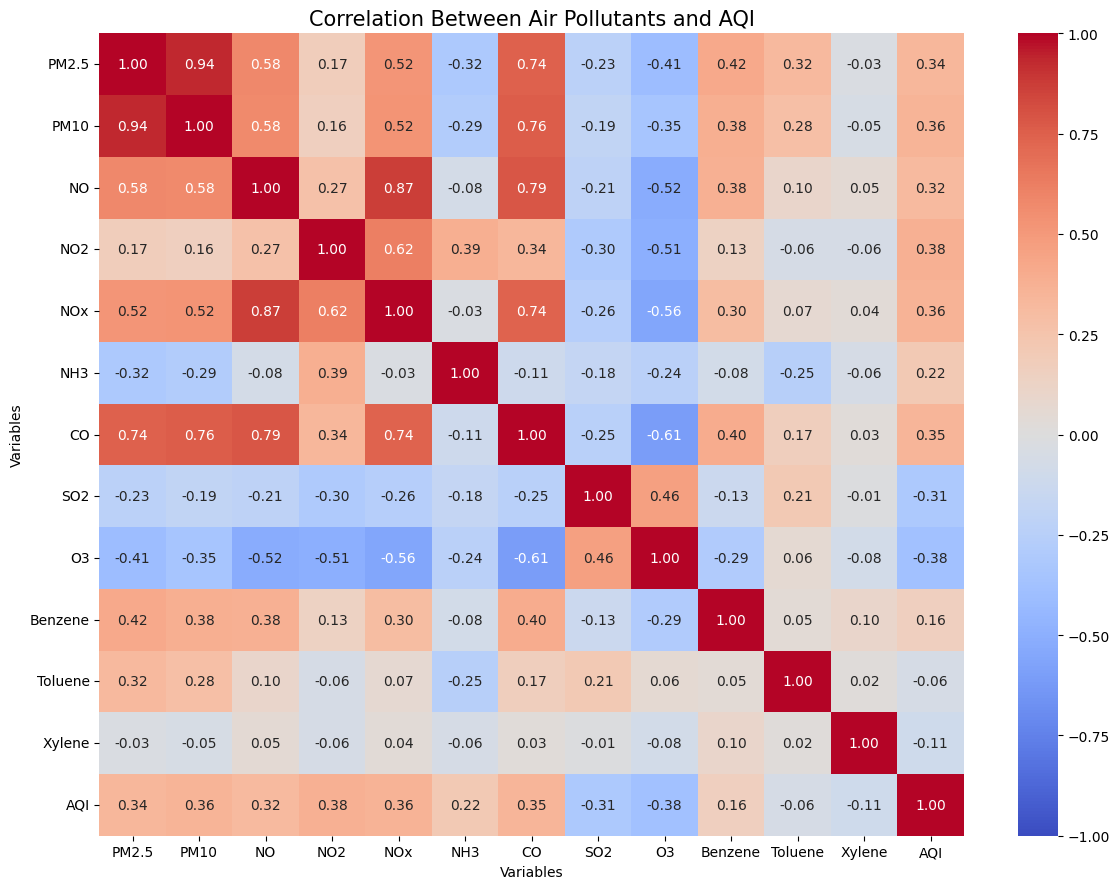


Correlation of each pollutant with AQI:
NO2        0.378
NOx        0.361
PM10       0.357
CO         0.345
PM2.5      0.343
NO         0.320
NH3        0.218
Benzene    0.157
Toluene   -0.056
Xylene    -0.107
SO2       -0.313
O3        -0.378
Name: AQI, dtype: float64

Strongest pollutant-AQI association:
Pollutant: NO2
Correlation: 0.378


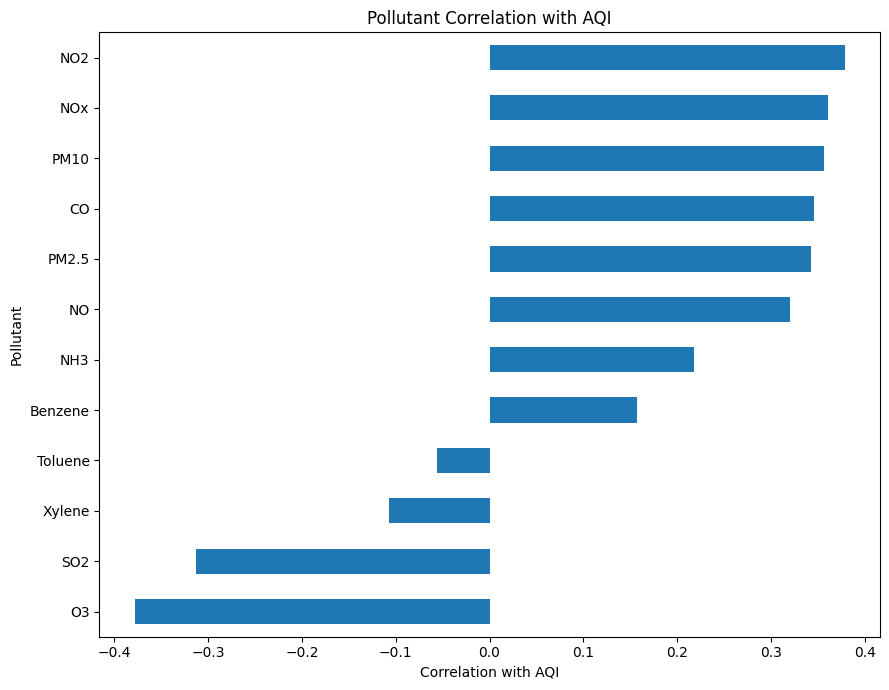

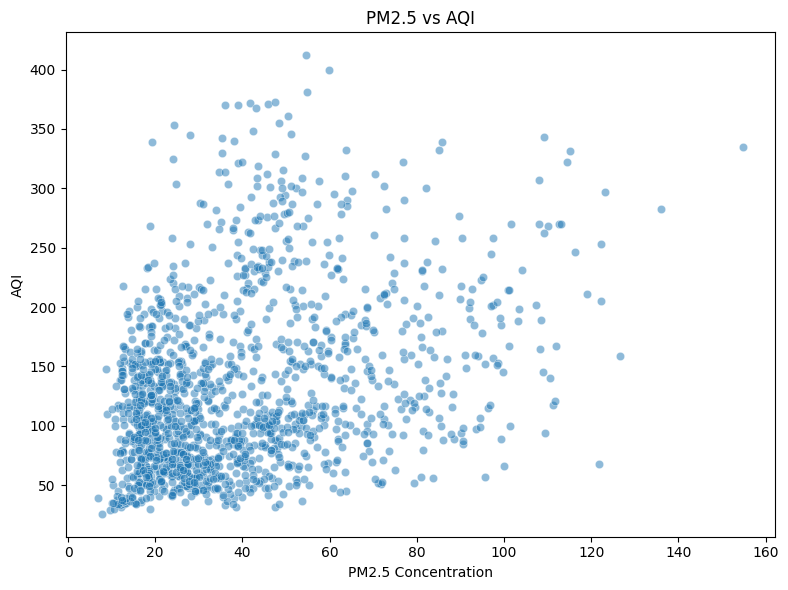

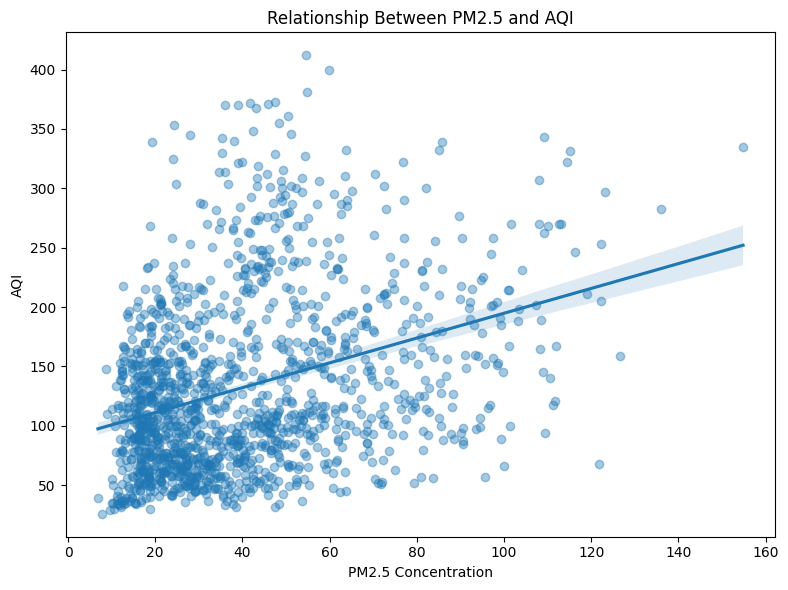

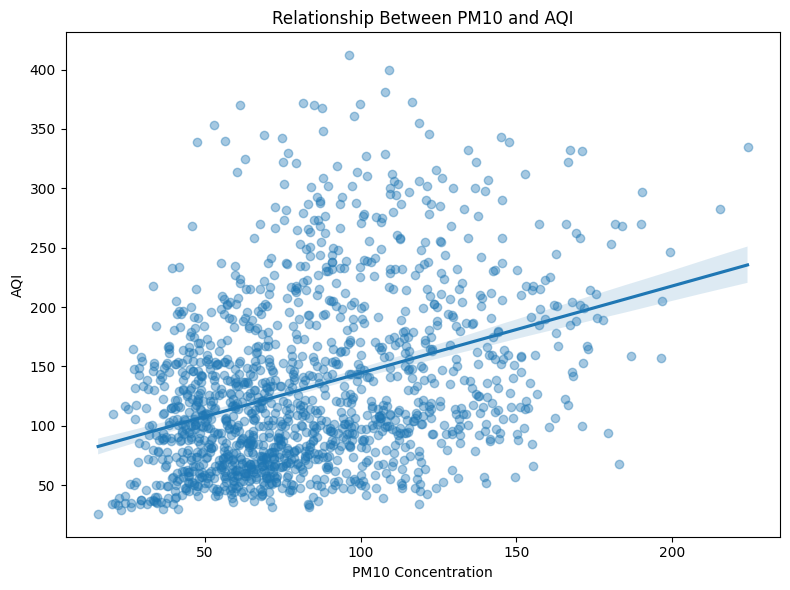

PM2.5 correlation with AQI: 0.343
PM10 correlation with AQI: 0.357

PM10 has the stronger correlation with AQI.


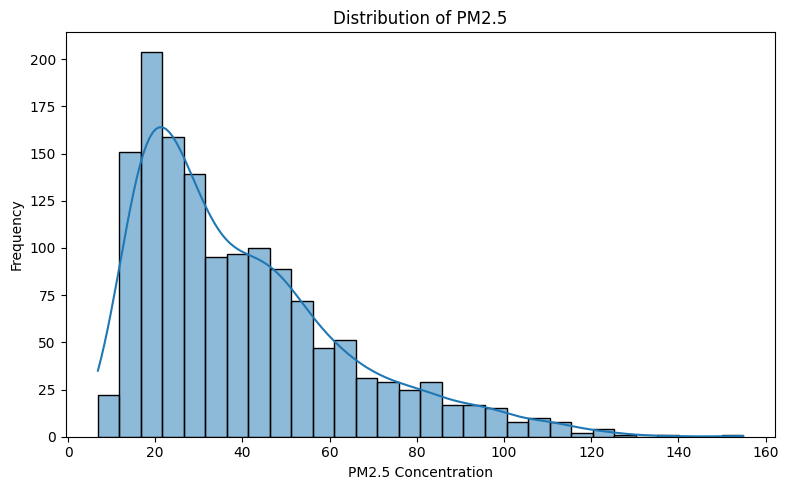

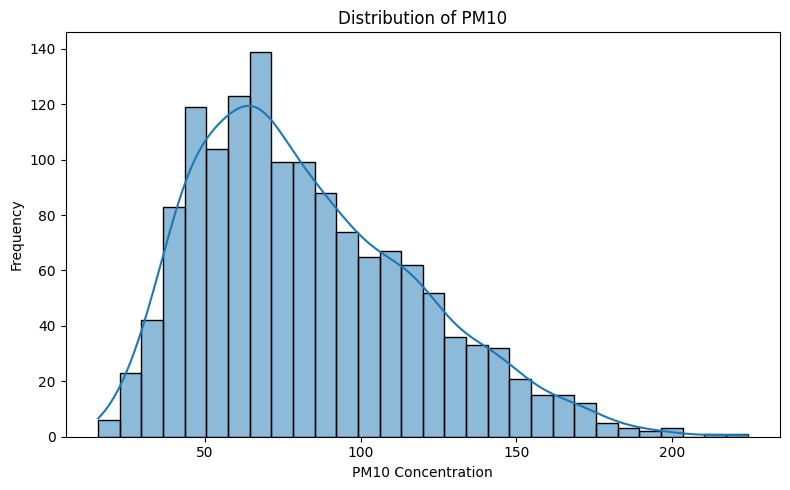

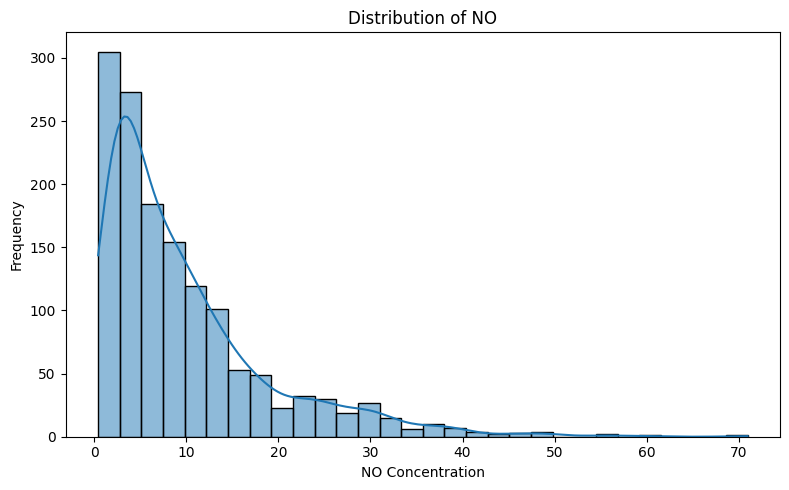

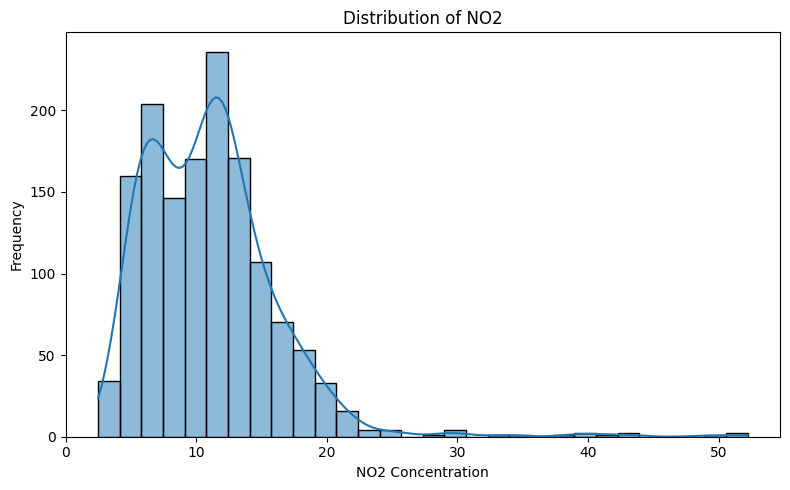

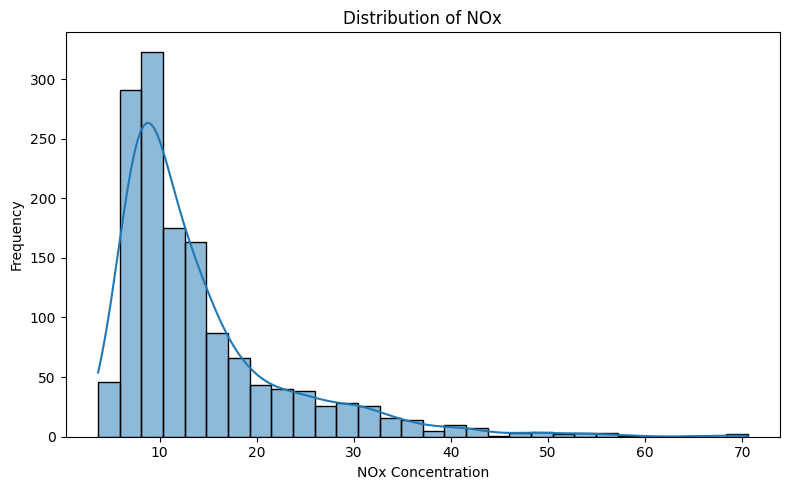

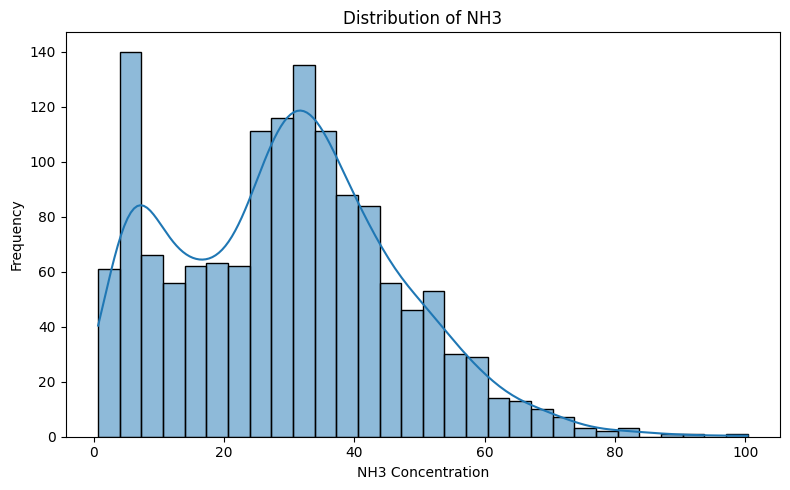

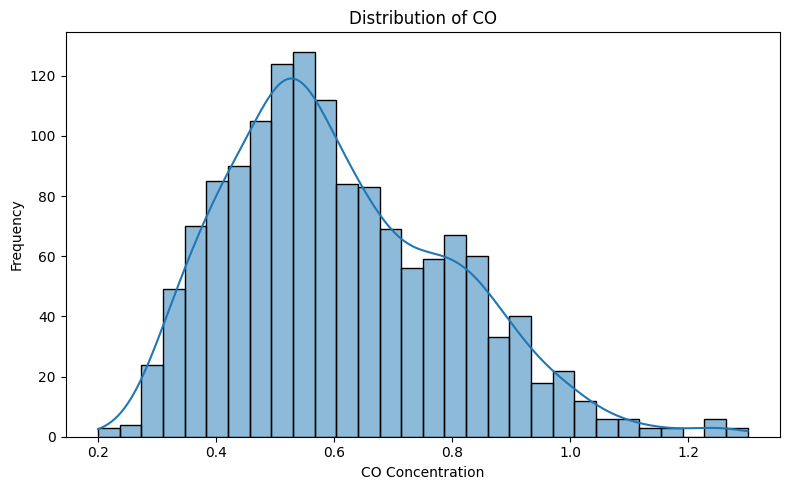

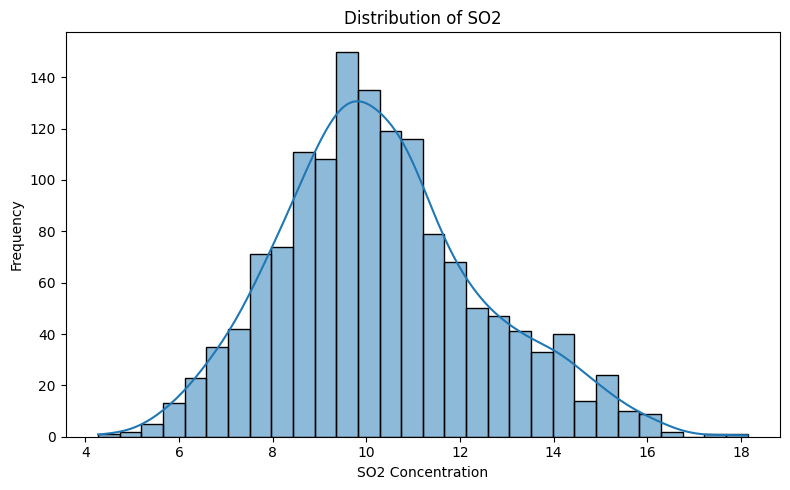

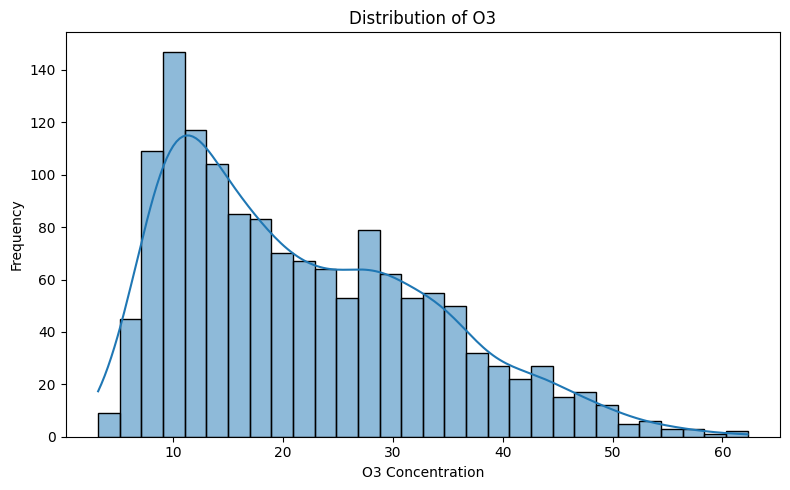

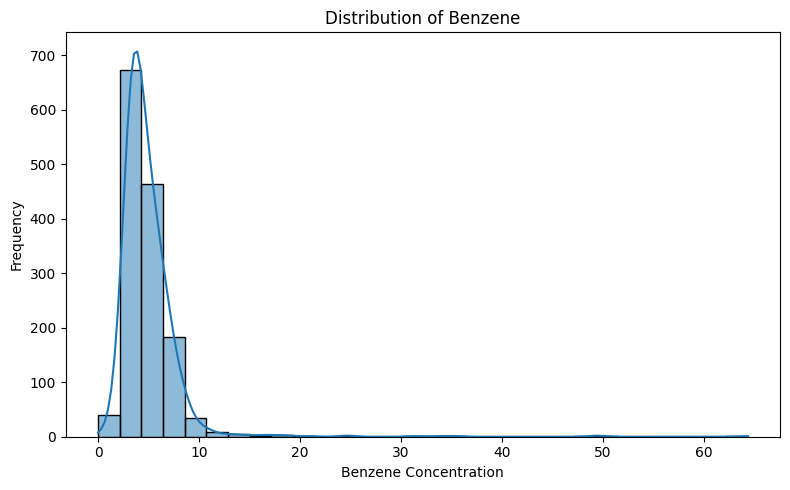

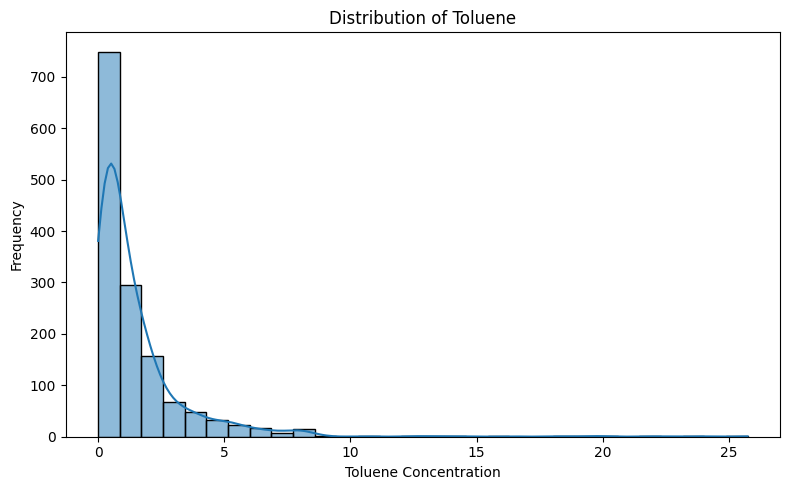

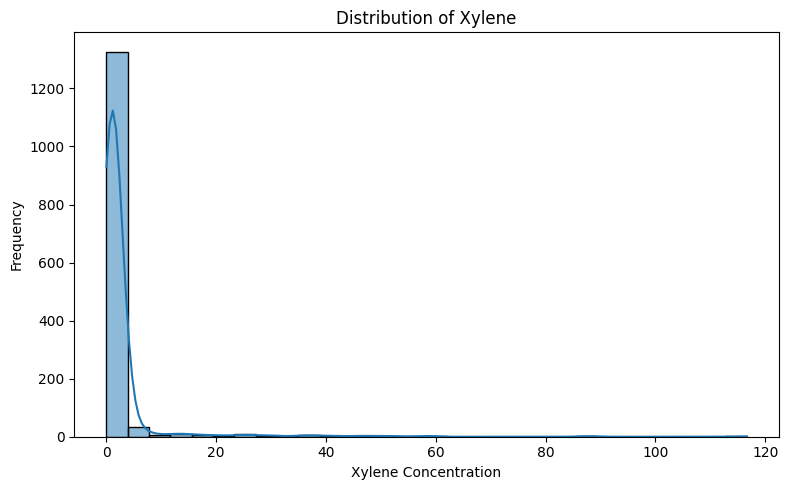


Descriptive Statistics:
          count   mean    std    min    25%    50%     75%     max
PM2.5    1424.0  39.95  23.88   6.86  21.18  33.10   52.06  154.85
PM10     1424.0  83.18  35.41  15.78  56.37  76.47  106.44  224.22
NO       1424.0   9.77   9.22   0.44   3.04   6.86   12.93   70.94
NO2      1424.0  11.01   5.22   2.47   7.08  10.74   13.40   52.22
NOx      1424.0  14.16   9.08   3.66   8.25  10.90   16.56   70.53
NH3      1424.0  29.48  17.03   0.65  15.45  29.90   40.40  100.35
CO       1424.0   0.61   0.19   0.20   0.47   0.57    0.74    1.30
SO2      1424.0  10.31   2.17   4.27   8.81  10.10   11.59   18.14
O3       1424.0  21.82  11.72   3.20  11.75  19.26   29.98   62.28
Benzene  1424.0   4.94   3.43   0.00   3.36   4.28    5.79   64.33
Toluene  1424.0   1.50   2.17   0.00   0.34   0.79    1.78   25.74
Xylene   1424.0   2.56   7.42   0.00   0.83   1.04    1.41  116.62

Top 10 PM2.5 pollution days:
      Date    PM2.5     PM10  AQI
28-10-2019 154.8500 224.2200  335
03-11-

In [7]:
# ============================================================
# DUTY 2: POLLUTANT & CORRELATION ANALYSIS
# Chandigarh Air Quality Dataset
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

# pandas: used for reading and manipulating the dataset
import pandas as pd

# numpy: used for numerical operations
import numpy as np

# matplotlib: used for creating plots
import matplotlib.pyplot as plt

# seaborn: used for statistical visualizations such as
# correlation heatmaps and regression plots
import seaborn as sns

# ------------------------------------------------------------
# 2. LOAD THE FINAL PROCESSED DATASET
# ------------------------------------------------------------


df = pd.read_csv("/content/chandigarh_temporal_features.csv")

# Upload the CSV file from your computer
from google.colab import files

uploaded = files.upload()

# Display the number of rows and columns
print("Dataset shape:", df.shape)


# Display the first 5 rows to understand the structure of the data
print("\nFirst 5 rows:")
print(df.head())


# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 3. DEFINE POLLUTANT COLUMNS
# ------------------------------------------------------------

# These are the pollutant variables available in our dataset.
# We will use these variables for correlation and distribution analysis.

pollutants = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Xylene"
]


# AQI is our overall air-quality indicator.
target = "AQI"


# Display the pollutants being analyzed
print("Pollutants being analyzed:")
print(pollutants)

# ------------------------------------------------------------
# 4. CONVERT POLLUTANT DATA TO NUMERIC FORMAT
# ------------------------------------------------------------

# Sometimes values read from a CSV can be interpreted as text.
# We convert all pollutant and AQI columns to numerical values.
#
# errors="coerce" means that any value that cannot be converted
# into a number will be changed to NaN (missing value).

for col in pollutants + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# Check the data types after conversion
print("\nData types:")
print(df[pollutants + [target]].dtypes)

# ------------------------------------------------------------
# 5. CHECK FOR MISSING VALUES
# ------------------------------------------------------------

# Count the number of missing values in each pollutant column
# and in AQI.

missing_values = df[pollutants + [target]].isnull().sum()

print("\nMissing values:")
print(missing_values)
# Calculate the percentage of missing values in each column

missing_percentage = (
    df[pollutants + [target]].isnull().mean() * 100
).round(2)


print("\nMissing value percentage:")
print(missing_percentage)

# ------------------------------------------------------------
# 6. CALCULATE CORRELATION MATRIX
# ------------------------------------------------------------

# Select only pollutant columns and AQI
# because these are the variables we want to compare.

corr_data = df[pollutants + ["AQI"]]


# Calculate Pearson correlation between all selected variables.
#
# Correlation values range from -1 to +1:
# +1  = strong positive relationship
#  0  = no linear relationship
# -1  = strong negative relationship

correlation_matrix = corr_data.corr()


# Display the correlation matrix rounded to 2 decimal places

print("\nCorrelation Matrix:")
print(correlation_matrix.round(2))

# ------------------------------------------------------------
# 7. CORRELATION HEATMAP
# ------------------------------------------------------------

# Set the size of the figure
plt.figure(figsize=(12, 9))


# Create the heatmap
sns.heatmap(
    correlation_matrix,

    # Display the numerical correlation value inside each cell
    annot=True,

    # Show values with 2 decimal places
    fmt=".2f",

    # Use a diverging color scheme
    # for negative → zero → positive correlations
    cmap="coolwarm",

    # Correlation ranges from -1 to +1
    vmin=-1,
    vmax=1,

    # Make zero the center of the color scale
    center=0
)


# Add title and labels
plt.title("Correlation Between Air Pollutants and AQI", fontsize=15)

plt.xlabel("Variables")
plt.ylabel("Variables")


# Prevent labels from being cut off
plt.tight_layout()


# Display the graph
plt.show()

# ------------------------------------------------------------
# 8. FIND POLLUTANTS MOST STRONGLY CORRELATED WITH AQI
# ------------------------------------------------------------

# Extract only the AQI correlation values.
# We remove AQI itself because AQI has a correlation of 1
# with itself, which is not useful for our analysis.

aqi_correlations = correlation_matrix["AQI"].drop("AQI")


# Sort pollutants from highest to lowest correlation

aqi_correlations_sorted = aqi_correlations.sort_values(
    ascending=False
)


print("\nCorrelation of each pollutant with AQI:")
print(aqi_correlations_sorted.round(3))

# ------------------------------------------------------------
# 9. IDENTIFY THE STRONGEST AQI ASSOCIATION
# ------------------------------------------------------------

# Find the pollutant with the largest absolute correlation.
#
# We use abs() because both strong positive and strong negative
# relationships are important.

strongest_pollutant = aqi_correlations.abs().idxmax()

strongest_correlation = aqi_correlations[strongest_pollutant]


print("\nStrongest pollutant-AQI association:")
print("Pollutant:", strongest_pollutant)
print("Correlation:", round(strongest_correlation, 3))

# ------------------------------------------------------------
# 10. POLLUTANT-AQI CORRELATION RANKING
# ------------------------------------------------------------

# Sort correlations from lowest to highest so that the
# horizontal bar chart is easier to read.

plot_data = aqi_correlations.sort_values(ascending=True)


# Create the figure
plt.figure(figsize=(9, 7))


# Create a horizontal bar chart
plot_data.plot(kind="barh")


# Add labels and title
plt.xlabel("Correlation with AQI")
plt.ylabel("Pollutant")
plt.title("Pollutant Correlation with AQI")


# Adjust spacing
plt.tight_layout()


# Display the graph
plt.show()

# ------------------------------------------------------------
# 11. PM2.5 VS AQI
# ------------------------------------------------------------

# Create a scatter plot to examine the relationship
# between PM2.5 concentration and AQI.

plt.figure(figsize=(8, 6))


sns.scatterplot(
    data=df,
    x="PM2.5",
    y="AQI",

    # Make points slightly transparent so overlapping
    # observations are easier to see.
    alpha=0.5
)


# Add title and axis labels
plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("AQI")


plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. PM2.5 VS AQI WITH REGRESSION LINE
# ------------------------------------------------------------

# A regression line helps us visualize the overall
# direction of the relationship.

plt.figure(figsize=(8, 6))


sns.regplot(
    data=df,
    x="PM2.5",
    y="AQI",

    # Make individual points transparent
    scatter_kws={"alpha": 0.4}
)


plt.title("Relationship Between PM2.5 and AQI")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("AQI")


plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. PM10 VS AQI WITH REGRESSION LINE
# ------------------------------------------------------------

# Examine the relationship between PM10 concentration
# and AQI.

plt.figure(figsize=(8, 6))


sns.regplot(
    data=df,
    x="PM10",
    y="AQI",

    # Make individual observations transparent
    scatter_kws={"alpha": 0.4}
)


plt.title("Relationship Between PM10 and AQI")
plt.xlabel("PM10 Concentration")
plt.ylabel("AQI")


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. COMPARE PM2.5 AND PM10 CORRELATIONS WITH AQI
# ------------------------------------------------------------

pm25_corr = correlation_matrix.loc["PM2.5", "AQI"]
pm10_corr = correlation_matrix.loc["PM10", "AQI"]


print("PM2.5 correlation with AQI:", round(pm25_corr, 3))
print("PM10 correlation with AQI:", round(pm10_corr, 3))


# Determine which one has the stronger absolute correlation

if abs(pm25_corr) > abs(pm10_corr):
    print("\nPM2.5 has the stronger correlation with AQI.")
elif abs(pm10_corr) > abs(pm25_corr):
    print("\nPM10 has the stronger correlation with AQI.")
else:
    print("\nPM2.5 and PM10 have equal correlation with AQI.")

# ------------------------------------------------------------
# 15. POLLUTANT DISTRIBUTIONS
# ------------------------------------------------------------

# Create a histogram for each pollutant.
#
# Histograms help us understand:
# - Typical pollutant concentrations
# - Spread of the data
# - Skewed distributions
# - Possible extreme pollution values

for pollutant in pollutants:

    # Create a new figure for each pollutant
    plt.figure(figsize=(8, 5))


    # Create histogram
    sns.histplot(
        data=df,
        x=pollutant,

        # Divide the values into 30 intervals
        bins=30,

        # Add a smooth density curve
        kde=True
    )


    # Add labels
    plt.title(f"Distribution of {pollutant}")
    plt.xlabel(f"{pollutant} Concentration")
    plt.ylabel("Frequency")


    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------
# 16. DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

# Calculate basic statistical measures for all pollutants.
#
# These include:
# count, mean, standard deviation, minimum,
# quartiles and maximum.

pollutant_statistics = df[pollutants].describe().T


# Display the results rounded to 2 decimal places

print("\nDescriptive Statistics:")
print(pollutant_statistics.round(2))

# ------------------------------------------------------------
# 17. TOP 10 PM2.5 POLLUTION DAYS
# ------------------------------------------------------------

# Find the 10 observations with the highest PM2.5 values.

top_pm25 = df.nlargest(10, "PM2.5")


# Display useful information about those days

print("\nTop 10 PM2.5 pollution days:")

print(
    top_pm25[
        ["Date", "PM2.5", "PM10", "AQI"]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 18. TOP 10 PM10 POLLUTION DAYS
# ------------------------------------------------------------

# Find the 10 observations with the highest PM10 values.

top_pm10 = df.nlargest(10, "PM10")


# Display the date, PM2.5, PM10 and AQI for those days

print("\nTop 10 PM10 pollution days:")

print(
    top_pm10[
        ["Date", "PM2.5", "PM10", "AQI"]
    ].to_string(index=False)
)